# Tarefa 3 — Classificação de texto AI vs. Human com PyTorch

Este notebook implementa uma solução completa de **Deep Learning em PyTorch** para classificação binária de textos:

- `0 = Human` — texto escrito por uma pessoa;
- `1 = AI` — texto gerado por um modelo ou aplicação de Inteligência Artificial.


> Substitua `AI_Human.csv` pelo caminho correto do seu ficheiro. O CSV deve conter uma coluna de texto (`text` ou `Text`) e uma coluna de rótulo (`generated`, `label` ou `class`).

In [3]:
# 1. Imports, reprodutibilidade e configuração
import os
import re
import csv
import copy
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

SEED = 42
DATASET_PATH = "AI_Human.csv"
MODEL_PATH = "models/lstm_ai_human_best.pt"

# Configuração equilibrada para execução em CPU ou GPU
MAX_EXAMPLES_PER_CLASS = 25000
MAX_VOCAB_SIZE = 20000
MIN_FREQ = 2
MAX_LEN = 96
BATCH_SIZE = 128
EMBED_DIM = 64
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
EPOCHS = 6
PATIENCE = 2
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Dispositivo:", DEVICE)
print("CUDA disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Aviso: o treino será executado na CPU.")

Dispositivo: cpu
CUDA disponível: False
Aviso: o treino será executado na CPU.


## 2. Leitura do dataset e normalização dos rótulos

A leitura é feita a partir do dataset do próprio trabalho, e não a partir do `AG_NEWS`. Os rótulos são convertidos para a codificação binária exigida: `Human=0` e `AI=1`.

In [4]:
HUMAN_VALUES = {"0", "0.0", "false", "no", "n", "human", "humano", "real", "not generated"}
AI_VALUES = {"1", "1.0", "true", "yes", "y", "ai", "generated", "machine", "chatgpt", "gpt"}

def parse_label(value):
    v = str(value).strip().lower()
    if v in HUMAN_VALUES:
        return 0
    if v in AI_VALUES:
        return 1
    if "human" in v:
        return 0
    if any(k in v for k in ("ai", "gpt", "machine", "generated")):
        return 1
    raise ValueError(f"Rótulo não reconhecido: {value!r}")

def load_ai_human_csv(path):
    texts, labels = [], []
    with open(path, "r", encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)
        columns = [c for c in (reader.fieldnames or []) if c]
        text_col = next((c for c in columns if c.strip().lower() in {"text", "texto", "content"}), None)
        label_col = next((c for c in columns if c.strip().lower() in {"generated", "label", "class", "target"}), None)
        if text_col is None or label_col is None:
            raise ValueError(f"Colunas encontradas: {columns}. Necessárias: texto e rótulo.")
        print(f"Coluna de texto: {text_col!r} | coluna de rótulo: {label_col!r}")
        for row in reader:
            text = (row.get(text_col) or "").strip()
            if text:
                texts.append(text)
                labels.append(parse_label(row.get(label_col)))
    return texts, np.asarray(labels, dtype=np.int64)

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Não foi encontrado: {DATASET_PATH}")

texts, labels = load_ai_human_csv(DATASET_PATH)
print(f"Total de exemplos: {len(texts):,}")
print("Distribuição [Human=0, AI=1]:", np.bincount(labels, minlength=2))

Coluna de texto: 'text' | coluna de rótulo: 'generated'
Total de exemplos: 487,231
Distribuição [Human=0, AI=1]: [305797 181434]


In [5]:
# 3. Amostragem equilibrada e divisão estratificada

def limit_per_class(texts, labels, max_per_class=25000, seed=SEED):
    rng = np.random.RandomState(seed)
    texts = np.asarray(texts, dtype=object)
    labels = np.asarray(labels, dtype=np.int64)
    selected = []
    for cls in np.unique(labels):
        indices = np.where(labels == cls)[0]
        rng.shuffle(indices)
        selected.extend(indices[:max_per_class])
    rng.shuffle(selected)
    selected = np.asarray(selected, dtype=np.int64)
    return texts[selected].tolist(), labels[selected]

texts, labels = limit_per_class(texts, labels, MAX_EXAMPLES_PER_CLASS, SEED)
print(f"Exemplos utilizados: {len(texts):,}")
print("Distribuição [Human=0, AI=1]:", np.bincount(labels, minlength=2))

def stratified_split(texts, labels, train_frac=0.70, val_frac=0.15, seed=SEED):
    rng = np.random.RandomState(seed)
    texts = np.asarray(texts, dtype=object)
    labels = np.asarray(labels, dtype=np.int64)
    train_idx, val_idx, test_idx = [], [], []
    for cls in np.unique(labels):
        cls_idx = np.where(labels == cls)[0]
        rng.shuffle(cls_idx)
        n = len(cls_idx)
        n_train = int(n * train_frac)
        n_val = int(n * val_frac)
        train_idx.extend(cls_idx[:n_train])
        val_idx.extend(cls_idx[n_train:n_train+n_val])
        test_idx.extend(cls_idx[n_train+n_val:])
    for idx in (train_idx, val_idx, test_idx):
        rng.shuffle(idx)
    return (texts[train_idx].tolist(), labels[train_idx],
            texts[val_idx].tolist(), labels[val_idx],
            texts[test_idx].tolist(), labels[test_idx])

texts_train, y_train, texts_val, y_val, texts_test, y_test = stratified_split(texts, labels)
for name, y in (("treino", y_train), ("validação", y_val), ("teste", y_test)):
    print(f"{name:10s}: {len(y):,} exemplos | [Human, AI] = {np.bincount(y, minlength=2)}")

Exemplos utilizados: 50,000
Distribuição [Human=0, AI=1]: [25000 25000]
treino    : 35,000 exemplos | [Human, AI] = [17500 17500]
validação : 7,500 exemplos | [Human, AI] = [3750 3750]
teste     : 7,500 exemplos | [Human, AI] = [3750 3750]


## 4. Tokenização, vocabulário e codificação

Os embeddings serão **aprendidos durante o treino**. O vocabulário é construído apenas com o conjunto de treino para evitar fuga de informação da validação ou do teste.

In [6]:
TOKEN_RE = re.compile(r"[a-zA-Z]+(?:'[a-zA-Z]+)?|[0-9]+|[^\W_]+", re.UNICODE)
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

def tokenize(text):
    return TOKEN_RE.findall(str(text).lower())

def build_vocab(train_texts, max_size=MAX_VOCAB_SIZE, min_freq=MIN_FREQ):
    counter = Counter()
    for text in train_texts:
        counter.update(tokenize(text))
    itos = [PAD_TOKEN, UNK_TOKEN]
    itos.extend(token for token, freq in counter.most_common() if freq >= min_freq and token not in itos)
    itos = itos[:max_size]
    stoi = {token: i for i, token in enumerate(itos)}
    return stoi, itos

stoi, itos = build_vocab(texts_train)
PAD_IDX = stoi[PAD_TOKEN]
UNK_IDX = stoi[UNK_TOKEN]
print("Tamanho do vocabulário:", len(itos))
print("PAD_IDX:", PAD_IDX, "| UNK_IDX:", UNK_IDX)

Tamanho do vocabulário: 20000
PAD_IDX: 0 | UNK_IDX: 1


In [7]:
class AIHumanDataset(Dataset):
    def __init__(self, texts, labels, stoi, max_len=MAX_LEN):
        self.texts = texts
        self.labels = np.asarray(labels, dtype=np.int64)
        self.stoi = stoi
        self.max_len = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        tokens = tokenize(self.texts[index])[:self.max_len]
        ids = [self.stoi.get(token, UNK_IDX) for token in tokens]
        if not ids:
            ids = [UNK_IDX]
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[index], dtype=torch.long)

def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.stack(labels)

train_dataset = AIHumanDataset(texts_train, y_train, stoi)
val_dataset = AIHumanDataset(texts_val, y_val, stoi)
test_dataset = AIHumanDataset(texts_test, y_test, stoi)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, num_workers=NUM_WORKERS)

## 5. Modelo: Embedding + LSTM multicamada + classificação binária

A sequência é empacotada com `pack_padded_sequence`, para que os tokens `<pad>` não sejam tratados como conteúdo real. A representação utilizada para classificar cada texto é o estado oculto final da última camada da LSTM.

In [8]:
class LSTMTextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers, dropout, pad_idx, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        direction_factor = 2
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * direction_factor, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        # hidden: [num_layers * 2, batch, hidden_size]
        forward_last = hidden[-2]
        backward_last = hidden[-1]
        representation = torch.cat((forward_last, backward_last), dim=1)
        return self.classifier(self.dropout(representation))

model = LSTMTextClassifier(
    vocab_size=len(stoi),
    embed_dim=EMBED_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
    num_classes=2
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)
print(model)
print(f"Parâmetros treináveis: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

LSTMTextClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Parâmetros treináveis: 1,346,818


# 6. Métricas e funções de treino/validação

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    result, f1_values = {}, []
    for cls, name in ((0, "human"), (1, "ai")):
        tp = int(np.sum((y_true == cls) & (y_pred == cls)))
        fp = int(np.sum((y_true != cls) & (y_pred == cls)))
        fn = int(np.sum((y_true == cls) & (y_pred != cls)))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        result[f"precision_{name}"] = precision
        result[f"recall_{name}"] = recall
        result[f"f1_{name}"] = f1
        f1_values.append(f1)
    result["accuracy"] = float(np.mean(y_true == y_pred))
    result["macro_f1"] = float(np.mean(f1_values))
    result["confusion_matrix"] = np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ], dtype=np.int64)
    return result

def run_epoch(model, loader, criterion, optimizer=None, max_batches=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_items, all_targets, all_preds = 0.0, 0, [], []
    for batch_idx, (input_ids, lengths, targets) in enumerate(loader):
        if max_batches is not None and batch_idx >= max_batches:
            break
        input_ids, lengths, targets = input_ids.to(DEVICE), lengths.to(DEVICE), targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids, lengths)
        loss = criterion(logits, targets)
        if training:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item() * targets.size(0)
        total_items += targets.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
    metrics = binary_metrics(all_targets, all_preds)
    metrics["loss"] = total_loss / max(total_items, 1)
    return metrics

In [10]:
def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    result = {}
    f1_values = []
    for cls, name in ((0, "human"), (1, "ai")):
        tp = int(np.sum((y_true == cls) & (y_pred == cls)))
        fp = int(np.sum((y_true != cls) & (y_pred == cls)))
        fn = int(np.sum((y_true == cls) & (y_pred != cls)))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        result[f"precision_{name}"] = precision
        result[f"recall_{name}"] = recall
        result[f"f1_{name}"] = f1
        f1_values.append(f1)
    result["accuracy"] = float(np.mean(y_true == y_pred))
    result["macro_f1"] = float(np.mean(f1_values))
    result["confusion_matrix"] = np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ], dtype=np.int64)
    return result

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, all_targets, all_preds = 0.0, [], []
    for input_ids, lengths, targets in loader:
        input_ids, lengths, targets = input_ids.to(DEVICE), lengths.to(DEVICE), targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids, lengths)
        loss = criterion(logits, targets)
        if training:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item() * targets.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
    metrics = binary_metrics(all_targets, all_preds)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics

In [11]:
# 7. Treino com early stopping, redução da learning rate e checkpoint
history = {"train_loss": [], "val_loss": [], "train_macro_f1": [], "val_macro_f1": [], "train_accuracy": [], "val_accuracy": []}
best_val_loss = float("inf")
best_state = None
bad_epochs = 0

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics = run_epoch(model, val_loader, criterion)
    scheduler.step(val_metrics["loss"])
    current_lr = optimizer.param_groups[0]["lr"]
    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr={current_lr:.2e} | "
          f"train_loss={train_metrics['loss']:.4f} | val_loss={val_metrics['loss']:.4f} | "
          f"train_macro_f1={train_metrics['macro_f1']:.4f} | val_macro_f1={val_metrics['macro_f1']:.4f}")
    if val_metrics["loss"] < best_val_loss - 1e-4:
        best_val_loss = val_metrics["loss"]
        best_state = copy.deepcopy(model.state_dict())
        bad_epochs = 0
        os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
        torch.save({"model_state_dict": best_state, "stoi": stoi,
                    "config": {"embed_dim": EMBED_DIM, "hidden_size": HIDDEN_SIZE,
                               "num_layers": NUM_LAYERS, "dropout": DROPOUT,
                               "max_len": MAX_LEN, "pad_idx": PAD_IDX}}, MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping ativado.")
            break
if best_state is not None:
    model.load_state_dict(best_state)
print("Melhor modelo guardado em:", MODEL_PATH)

Epoch 01/6 | lr=1.00e-03 | train_loss=0.4137 | val_loss=0.3063 | train_macro_f1=0.7985 | val_macro_f1=0.8957
Epoch 02/6 | lr=1.00e-03 | train_loss=0.1787 | val_loss=0.5470 | train_macro_f1=0.9316 | val_macro_f1=0.8589
Epoch 03/6 | lr=5.00e-04 | train_loss=0.1296 | val_loss=0.4032 | train_macro_f1=0.9519 | val_macro_f1=0.8880
Early stopping ativado.
Melhor modelo guardado em: models/lstm_ai_human_best.pt


## 7. Curvas de aprendizagem

As curvas devem ser analisadas procurando uma diferença excessiva entre treino e validação. Um aumento da perda de validação enquanto a perda de treino continua a diminuir é um sinal de *overfitting*.

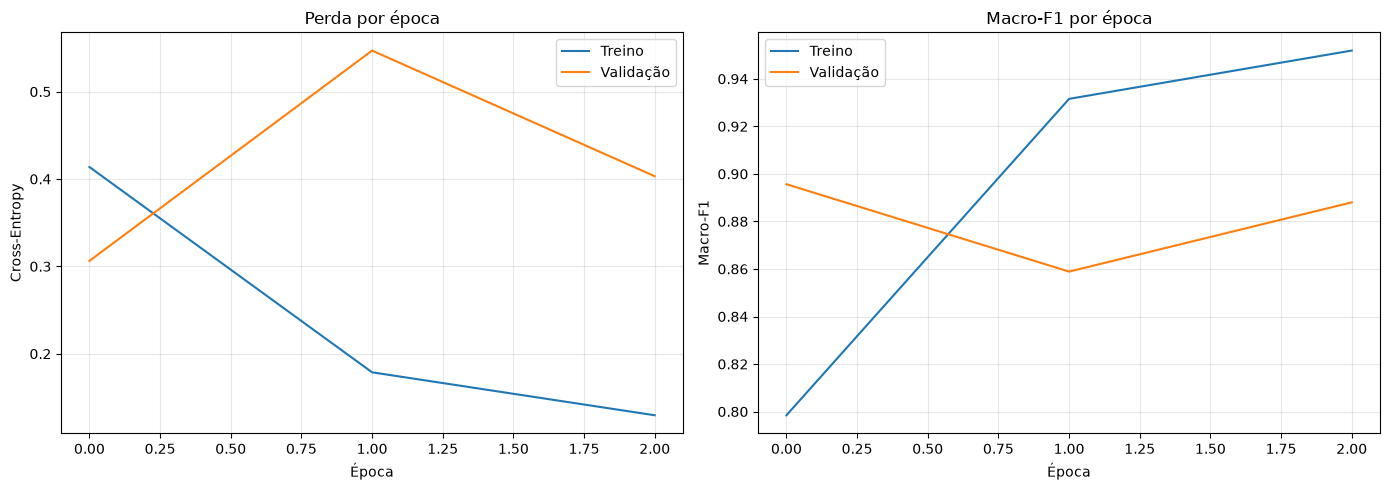

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history["train_loss"], label="Treino")
axes[0].plot(history["val_loss"], label="Validação")
axes[0].set_title("Perda por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["train_macro_f1"], label="Treino")
axes[1].plot(history["val_macro_f1"], label="Validação")
axes[1].set_title("Macro-F1 por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Avaliação final no conjunto de teste

Esta é a primeira utilização do conjunto de teste para medir o desempenho final. O modelo não foi escolhido nem ajustado com base nestes exemplos.

In [13]:
test_metrics = run_epoch(model, test_loader, criterion)
print("=== RESULTADOS FINAIS — TESTE ===")
print(f"Loss:       {test_metrics['loss']:.4f}")
print(f"Accuracy:   {test_metrics['accuracy']:.4f}")
print(f"Macro-F1:   {test_metrics['macro_f1']:.4f}")
print()
for name in ("human", "ai"):
    print(f"Classe {name.upper()}: "
          f"precision={test_metrics['precision_'+name]:.4f} | "
          f"recall={test_metrics['recall_'+name]:.4f} | "
          f"f1={test_metrics['f1_'+name]:.4f}")
print("\nMatriz de confusão [linhas=real, colunas=previsto]:")
print(test_metrics["confusion_matrix"])

=== RESULTADOS FINAIS — TESTE ===
Loss:       0.2948
Accuracy:   0.8961
Macro-F1:   0.8957

Classe HUMAN: precision=0.8493 | recall=0.9632 | f1=0.9027
Classe AI: precision=0.9575 | recall=0.8291 | f1=0.8887

Matriz de confusão [linhas=real, colunas=previsto]:
[[3612  138]
 [ 641 3109]]


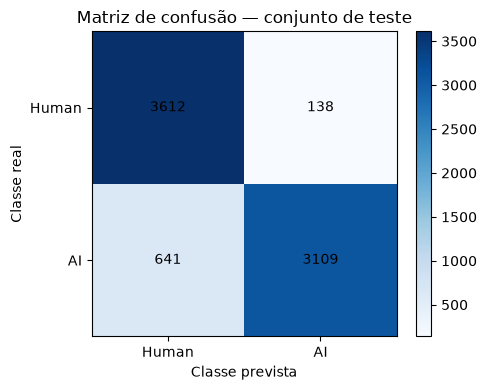

In [14]:
# 9. Matriz de confusão visual
cm = test_metrics["confusion_matrix"]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["Human", "AI"])
ax.set_yticks([0, 1], labels=["Human", "AI"])
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de confusão — conjunto de teste")
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 9. Inferência em novos textos

In [15]:
def predict_texts(model, new_texts):
    model.eval()
    encoded = []
    for text in new_texts:
        ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)[:MAX_LEN]] or [UNK_IDX]
        encoded.append(torch.tensor(ids, dtype=torch.long))
    lengths = torch.tensor([len(x) for x in encoded], dtype=torch.long)
    batch = pad_sequence(encoded, batch_first=True, padding_value=PAD_IDX).to(DEVICE)
    with torch.no_grad():
        probabilities = torch.softmax(model(batch, lengths.to(DEVICE)), dim=1)[:, 1]
    return [("AI" if p.item() >= 0.5 else "Human", float(p.item())) for p in probabilities]

examples = [
    "This paragraph was written as a demonstration of a text classification system.",
    "The experimental results indicate that the proposed method improves the measured performance."
]
print(predict_texts(model, examples))

[('Human', 0.12877778708934784), ('AI', 0.7632015943527222)]
